# Лабораторная работа №3: оптимизация гиперпараметров

**Цель:** корректно подобрать гиперпараметры модели с помощью кросс-валидации,
сравнить Grid Search и Random Search и исследовать влияние параметров на качество.

Использована задача лабораторной №2 — предсказание выживания пассажиров Titanic
(`Survived`). Модель — `RandomForestClassifier`, основная метрика — **F1 класса 1**.
F1 учитывает одновременно precision и recall, поэтому информативнее одной accuracy
при несбалансированных классах и различной важности ошибок.

Ноутбук самодостаточен: данные встроены внутрь файла в сжатом виде. Все результаты
получены при `random_state=42`.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/lab3-matplotlib")

import base64
import gzip
import io
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold,
    cross_validate, train_test_split, validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TEST_SIZE = 0.20
SCORING = "f1"
pd.set_option("display.max_colwidth", 120)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Сжатая копия Titanic CSV. Ячейка обычно скрывается при экспорте отчёта.
TITANIC_GZIP_BASE64 = "..."
df = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(TITANIC_GZIP_BASE64))))
print(f"Размер данных: {df.shape[0]} объектов, {df.shape[1]} исходных столбцов")
display(df.head(3))

Размер данных: 891 объектов, 12 исходных столбцов


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


## 1. Подготовка данных и честный эксперимент

Используются те же семь признаков, что в лабораторной №2: `Pclass`, `Sex`, `Age`,
`SibSp`, `Parch`, `Fare`, `Embarked`. Идентификаторы, имя, номер билета и каюта
исключены. Данные один раз разделяются на train (80%) и test (20%) со
стратификацией.

Импутация и one-hot encoding помещены внутрь `Pipeline`. Поэтому при
кросс-валидации преобразования обучаются только на тренировочной части каждого
fold, что предотвращает утечку. Тестовая выборка ниже не используется до раздела
с финальной оценкой.

In [3]:
numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]
feature_cols = categorical_features + numeric_features

X = df[feature_cols].copy()
X["Pclass"] = X["Pclass"].astype(str)
y = df["Survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

def make_model(**params):
    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])
    pipe = Pipeline([
        ("prep", preprocessing),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    return pipe.set_params(**params)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доля Survived=1 — train:", round(y_train.mean(), 3),
      "test:", round(y_test.mean(), 3))

Train: (712, 7) Test: (179, 7)
Доля Survived=1 — train: 0.383 test: 0.385


## 2. Baseline и выбранные гиперпараметры

Baseline — зафиксированная модель Random Forest из лабораторной №2:
`n_estimators=150`, `max_depth=4`, `min_samples_leaf=1`,
`max_features='sqrt'`.

Исследуются четыре параметра:

| Параметр | Смысл и ожидаемое влияние | Разумный диапазон |
|---|---|---|
| `n_estimators` | Число деревьев. Рост обычно снижает дисперсию и повышает устойчивость, но увеличивает время; затем качество выходит на плато. | 50–600 |
| `max_depth` | Максимальная глубина дерева. Малая глубина вызывает недообучение, чрезмерная может привести к запоминанию train. | 2–12 и без ограничения |
| `min_samples_leaf` | Минимум объектов в листе. Рост регуляризует дерево; слишком большое значение сглаживает полезные закономерности. | 1–8 в поиске, до 30 в анализе |
| `max_features` | Число признаков-кандидатов в узле. Меньшее значение делает деревья разнообразнее, но слабее; большое — более похожими. | `sqrt`, `log2`, 0,2–1,0 |

In [4]:
baseline_params = {
    "model__n_estimators": 150,
    "model__max_depth": 4,
    "model__min_samples_leaf": 1,
    "model__max_features": "sqrt",
}
baseline_cv = cross_validate(
    make_model(**baseline_params), X_train, y_train,
    scoring=SCORING, cv=cv, return_train_score=True, n_jobs=-1,
)
print(f"Baseline CV F1: {baseline_cv['test_score'].mean():.4f} "
      f"± {baseline_cv['test_score'].std():.4f}")

Baseline CV F1: 0.7373 ± 0.0329


## 3. Кросс-валидация

Используется `StratifiedKFold` с 5 folds, перемешиванием и `random_state=42`.
Стратификация сохраняет долю классов. Пять folds — компромисс между надёжностью
оценки и временем: каждая комбинация пять раз проверяется на разных 20% train.

**Зачем нужна CV?** Она оценивает обобщающую способность модели и уменьшает
зависимость вывода от единственного случайного разбиения.

**Почему одного train/test недостаточно?** Состав одной validation-части может
случайно оказаться лёгким или сложным. Тогда будут выбраны параметры, выигравшие
на конкретном разбиении, а не устойчиво работающие параметры.

**Что будет при многократном выборе по test?** Информация о test неявно попадёт в
подбор. Оценка станет оптимистичной, а test перестанет быть независимой имитацией
новых данных. Поэтому все решения здесь принимаются только по train CV.

## 4. Grid Search и Random Search

In [5]:
grid_space = {
    "model__n_estimators": [100, 150, 300],
    "model__max_depth": [3, 4, 6, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
}
random_space = {
    "model__n_estimators": [50, 100, 150, 200, 300, 400, 600],
    "model__max_depth": [None, 2, 3, 4, 6, 8, 12],
    "model__min_samples_leaf": [1, 2, 3, 4, 6, 8],
    "model__max_features": ["sqrt", "log2", 0.5],
}

grid_search = GridSearchCV(
    make_model(), grid_space, scoring=SCORING, cv=cv,
    n_jobs=-1, return_train_score=True, refit=True,
)
started = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = time.perf_counter() - started

random_search = RandomizedSearchCV(
    make_model(), random_space, n_iter=72, scoring=SCORING, cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True, refit=True,
)
started = time.perf_counter()
random_search.fit(X_train, y_train)
random_seconds = time.perf_counter() - started

def clean_params(params):
    return {key.removeprefix("model__"): value for key, value in params.items()}

search_comparison = pd.DataFrame([
    {
        "Метод": "Grid Search",
        "Комбинаций": len(grid_search.cv_results_["params"]),
        "Лучший CV F1": grid_search.best_score_,
        "Время, с": grid_seconds,
        "Лучшие параметры": clean_params(grid_search.best_params_),
    },
    {
        "Метод": "Random Search",
        "Комбинаций": len(random_search.cv_results_["params"]),
        "Лучший CV F1": random_search.best_score_,
        "Время, с": random_seconds,
        "Лучшие параметры": clean_params(random_search.best_params_),
    },
])
display(search_comparison.style.format({"Лучший CV F1": "{:.4f}", "Время, с": "{:.2f}"}))

,Метод,Комбинаций,Лучший CV F1,"Время, с",Лучшие параметры
0,Grid Search,72,0.7566,13.50,"{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 100}"
1,Random Search,72,0.7480,15.45,"{'n_estimators': 150, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 8}"


In [6]:
display(Markdown(f"""
**Grid Search.** Полная сетка содержит
$3 \\times 4 \\times 3 \\times 2 = 72$ комбинации. Лучший набор:
`{clean_params(grid_search.best_params_)}`. Средний CV F1 —
**{grid_search.best_score_:.4f}**, время — **{grid_seconds:.2f} с**.

**Random Search.** Пространство содержит 882 возможные комбинации, из них при
`random_state=42` проверено 72 — вычислительный бюджет сопоставим с Grid Search.
Лучший набор: `{clean_params(random_search.best_params_)}`. Средний CV F1 —
**{random_search.best_score_:.4f}**, время — **{random_seconds:.2f} с**.

В этом запуске Grid Search нашёл более высокое качество. Различие времени при
одинаковом числе комбинаций связано с тем, что Random Search проверяет модели с
400 и 600 деревьями. Случайный поиск особенно полезен при большом числе
параметров, широких или непрерывных диапазонах и ограниченном бюджете: он
исследует разные области, не перебирая полное декартово произведение сетки.
"""))


**Grid Search.** Полная сетка содержит
$3 \times 4 \times 3 \times 2 = 72$ комбинации. Лучший набор:
`{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 100}`. Средний CV F1 —
**0.7566**, время — **13.50 с**.

**Random Search.** Пространство содержит 882 возможные комбинации, из них при
`random_state=42` проверено 72 — вычислительный бюджет сопоставим с Grid Search.
Лучший набор: `{'n_estimators': 150, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 8}`. Средний CV F1 —
**0.7480**, время — **15.45 с**.

В этом запуске Grid Search нашёл более высокое качество. Различие времени при
одинаковом числе комбинаций связано с тем, что Random Search проверяет модели с
400 и 600 деревьями. Случайный поиск особенно полезен при большом числе
параметров, широких или непрерывных диапазонах и ограниченном бюджете: он
исследует разные области, не перебирая полное декартово произведение сетки.


## 5. Влияние гиперпараметров

Для каждого графика меняется один параметр, остальные фиксируются как у лучшей
модели Grid Search. Сравнение train и CV F1 позволяет увидеть недообучение и
переобучение.

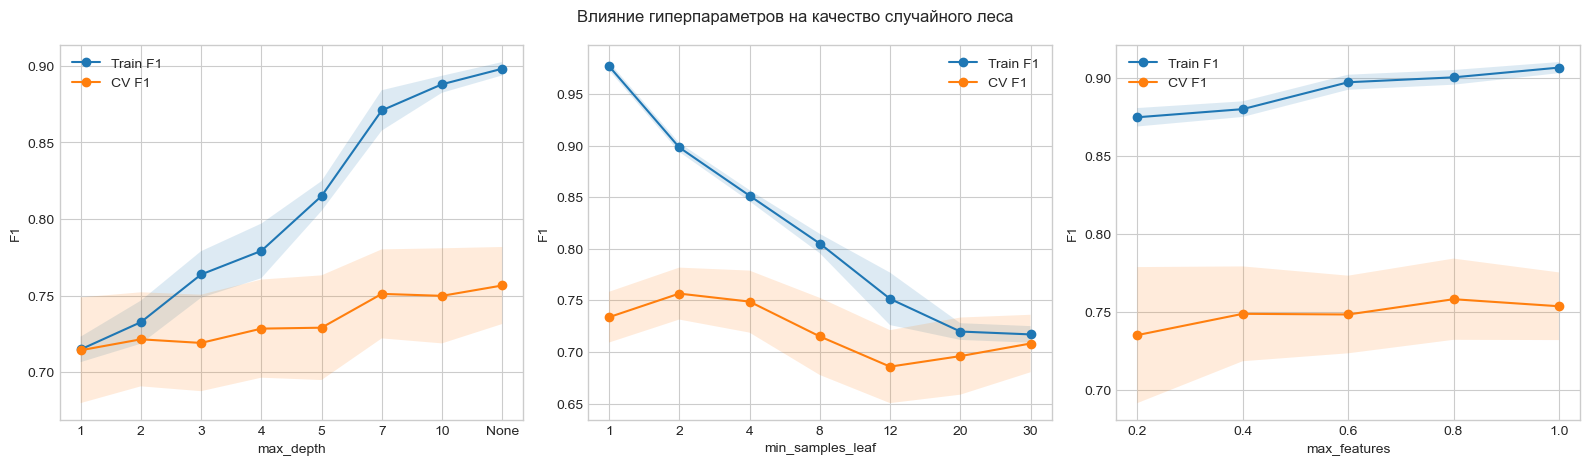

,Параметр,Значение,Train F1,CV F1,CV std
0,max_depth,1,0.7148,0.7143,0.0345
1,max_depth,2,0.7326,0.7214,0.0307
2,max_depth,3,0.7638,0.7190,0.0315
3,max_depth,4,0.7792,0.7284,0.0321
4,max_depth,5,0.8150,0.7290,0.0342
5,max_depth,7,0.8709,0.7511,0.0291
6,max_depth,10,0.8880,0.7498,0.0311
7,max_depth,None,0.8982,0.7566,0.0252
8,min_samples_leaf,1,0.9769,0.7337,0.0246
9,min_samples_leaf,2,0.8982,0.7566,0.0252


In [7]:
studies = [
    ("model__max_depth", [1, 2, 3, 4, 5, 7, 10, None],
     ["1", "2", "3", "4", "5", "7", "10", "None"]),
    ("model__min_samples_leaf", [1, 2, 4, 8, 12, 20, 30],
     ["1", "2", "4", "8", "12", "20", "30"]),
    ("model__max_features", [0.2, 0.4, 0.6, 0.8, 1.0],
     ["0.2", "0.4", "0.6", "0.8", "1.0"]),
]

curve_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
for ax, (name, values, labels) in zip(axes, studies):
    fixed = dict(grid_search.best_params_)
    fixed.pop(name, None)
    train_scores, cv_scores = validation_curve(
        make_model(**fixed), X_train, y_train,
        param_name=name, param_range=values,
        scoring=SCORING, cv=cv, n_jobs=-1,
    )
    pos = np.arange(len(values))
    train_mean, train_std = train_scores.mean(1), train_scores.std(1)
    cv_mean, cv_std = cv_scores.mean(1), cv_scores.std(1)
    ax.plot(pos, train_mean, "o-", label="Train F1")
    ax.fill_between(pos, train_mean-train_std, train_mean+train_std, alpha=.15)
    ax.plot(pos, cv_mean, "o-", label="CV F1")
    ax.fill_between(pos, cv_mean-cv_std, cv_mean+cv_std, alpha=.15)
    ax.set(xticks=pos, xticklabels=labels,
           xlabel=name.removeprefix("model__"), ylabel="F1")
    ax.legend()
    for value, tr, tr_std, val, val_std in zip(
        values, train_mean, train_std, cv_mean, cv_std
    ):
        curve_rows.append({
            "Параметр": name.removeprefix("model__"), "Значение": str(value),
            "Train F1": tr, "CV F1": val, "CV std": val_std,
        })
fig.suptitle("Влияние гиперпараметров на качество случайного леса")
fig.tight_layout()
plt.show()

curve_results = pd.DataFrame(curve_rows)
display(curve_results.style.format({"Train F1": "{:.4f}", "CV F1": "{:.4f}", "CV std": "{:.4f}"}))

**Интерпретация.**

- При `max_depth=1–3` обе метрики низкие: модель недообучена. Разумная сложность
  начинается примерно с глубины 7. У глубоких деревьев train F1 заметно выше CV
  F1, то есть риск переобучения растёт, хотя ансамблирование его смягчает.
- При `min_samples_leaf=1` train F1 почти равен 1, а CV заметно хуже — явное
  переобучение. Лучший компромисс даёт 2 объекта в листе. Значения 8–30 слишком
  сильно регуляризуют модель и ведут к недообучению.
- Для `max_features` разумная область находится около 0,4–0,8. При 0,2 отдельным
  деревьям доступно мало информации, а при 1,0 деревья становятся более похожими.

Основной признак переобучения — рост train-метрики одновременно с падением
CV-метрики; признак недообучения — низкие значения обеих метрик.

## 6. Устойчивость на отдельных folds

Модель,Baseline,Grid Search,Random Search
Fold,,,
1,0.7850,0.7810,0.7692
2,0.7273,0.7339,0.7290
3,0.7660,0.7921,0.7835
4,0.7059,0.7308,0.7500
5,0.7021,0.7451,0.7083


,Модель,Train F1,CV F1 mean,CV F1 std
0,Baseline,0.7779,0.7373,0.0329
1,Grid Search,0.8982,0.7566,0.0252
2,Random Search,0.8587,0.7480,0.0270


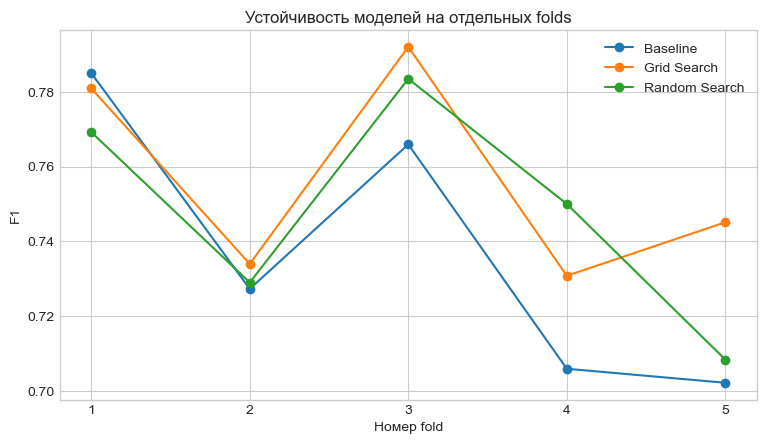

In [8]:
selected = {
    "Baseline": baseline_params,
    "Grid Search": grid_search.best_params_,
    "Random Search": random_search.best_params_,
}

cv_rows, fold_rows = [], []
for model_name, params in selected.items():
    scores = cross_validate(
        make_model(**params), X_train, y_train,
        scoring=SCORING, cv=cv, return_train_score=True, n_jobs=-1,
    )
    cv_rows.append({
        "Модель": model_name,
        "Train F1": scores["train_score"].mean(),
        "CV F1 mean": scores["test_score"].mean(),
        "CV F1 std": scores["test_score"].std(),
    })
    for fold, score in enumerate(scores["test_score"], 1):
        fold_rows.append({"Модель": model_name, "Fold": fold, "F1": score})

cv_summary = pd.DataFrame(cv_rows)
fold_scores = pd.DataFrame(fold_rows)
display(fold_scores.pivot(index="Fold", columns="Модель", values="F1").style.format("{:.4f}"))
display(cv_summary.style.format({
    "Train F1": "{:.4f}", "CV F1 mean": "{:.4f}", "CV F1 std": "{:.4f}"
}))

fig, ax = plt.subplots(figsize=(9, 4.8))
for model_name, group in fold_scores.groupby("Модель", sort=False):
    ax.plot(group["Fold"], group["F1"], "o-", label=model_name)
ax.set(xticks=range(1, 6), xlabel="Номер fold", ylabel="F1",
       title="Устойчивость моделей на отдельных folds")
ax.legend()
plt.show()

Две модели с одинаковым средним качеством могут различаться по устойчивости:
одна даёт близкий результат на всех folds, другая сильно зависит от состава
подвыборки. При сопоставимом среднем предпочтительнее меньшее стандартное
отклонение. В этом эксперименте Grid Search имеет одновременно лучшее среднее и
наименьший разброс.

## 7. Финальная оценка на test

Только теперь, после выбора всех параметров по train CV, модели обучаются на всей
обучающей выборке и оцениваются на отложенном test.

In [9]:
test_scores = {}
for model_name, params in selected.items():
    fitted = make_model(**params).fit(X_train, y_train)
    test_scores[model_name] = f1_score(y_test, fitted.predict(X_test))

final_table = cv_summary.copy()
final_table["Test F1"] = final_table["Модель"].map(test_scores)
display(final_table.style.format({
    "Train F1": "{:.4f}", "CV F1 mean": "{:.4f}",
    "CV F1 std": "{:.4f}", "Test F1": "{:.4f}",
}))

base = final_table.set_index("Модель").loc["Baseline"]
grid = final_table.set_index("Модель").loc["Grid Search"]
random = final_table.set_index("Модель").loc["Random Search"]

display(Markdown(f"""
## 8. Итоговый вывод

Финальной выбрана модель **Grid Search**:
`{clean_params(grid_search.best_params_)}`.

- Grid Search улучшил baseline на **{grid['CV F1 mean']-base['CV F1 mean']:.4f}**
  F1 по CV и на **{grid['Test F1']-base['Test F1']:.4f}** по test.
- Random Search улучшил baseline на
  **{random['CV F1 mean']-base['CV F1 mean']:.4f}** по CV и на
  **{random['Test F1']-base['Test F1']:.4f}** по test.
- Направление улучшения на CV и test совпало, но величина различается. Это
  объясняется статистическим разбросом: CV — среднее пяти оценок, а test содержит
  только {len(y_test)} других объектов.
- Grid Search дал лучший CV F1 (**{grid['CV F1 mean']:.4f}**), лучший test F1
  (**{grid['Test F1']:.4f}**) и наименьший разброс folds
  (**{grid['CV F1 std']:.4f}**).

Тестовая выборка не участвовала в построении пространств поиска или выборе
гиперпараметров. Таким образом, эксперимент удовлетворяет требованию честной
финальной проверки.
"""))

,Модель,Train F1,CV F1 mean,CV F1 std,Test F1
0,Baseline,0.7779,0.7373,0.0329,0.6838
1,Grid Search,0.8982,0.7566,0.0252,0.7287
2,Random Search,0.8587,0.7480,0.0270,0.7040



## 8. Итоговый вывод

Финальной выбрана модель **Grid Search**:
`{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 100}`.

- Grid Search улучшил baseline на **0.0193**
  F1 по CV и на **0.0449** по test.
- Random Search улучшил baseline на
  **0.0108** по CV и на
  **0.0202** по test.
- Направление улучшения на CV и test совпало, но величина различается. Это
  объясняется статистическим разбросом: CV — среднее пяти оценок, а test содержит
  только 179 других объектов.
- Grid Search дал лучший CV F1 (**0.7566**), лучший test F1
  (**0.7287**) и наименьший разброс folds
  (**0.0252**).

Тестовая выборка не участвовала в построении пространств поиска или выборе
гиперпараметров. Таким образом, эксперимент удовлетворяет требованию честной
финальной проверки.
